# 07 · Convergencia, resultados por celda y validación con 2018–2019
**Grupo 2 · Estadística Bayesiana · Entrega final**  
Jean Paul Rojas Rojas · Daniel Estiven Pacheco Villagrande · Diego Andrés Cascante Camacho

**Qué hace.** Grafica la convergencia, arma la tabla por celda (severidad, intervalos, P(top 10), niveles de prioridad), valida contra 2018–2019 (Spearman, Brier, log-loss, top 10, lpd, cobertura), revisa la equidad del error y la capacidad de 10 celdas, y comprueba que las cifras coinciden con el informe.

**Entradas.** `salidas/m1_resumen.npz` (de 05), `salidas/m2_resumen.npz` (de 06), `datos/siniestros_limpios.csv`.

**Salidas.** `salidas/figuras/trazas.png, autocorr_densidades.png, encogimiento.png, top20_forest.png, validacion.png`; `salidas/resultados/celdas_posterior.csv, validacion_2018_2019.csv, 07_validacion.json`.

*Respaldo por etapas: el notebook principal es `../Grupo2_Bayesiana_completo.ipynb`, que reúne estas ocho etapas.* Orden de ejecución y trazabilidad completa: `../README.md`.

In [1]:
# Configuración: funciona en Google Colab y en un computador
# En Colab: suba la carpeta "notebooks" a su Drive. Si el buscador automático no la encuentra,
# escriba su ruta en BASE_COLAB, p. ej. '/content/drive/MyDrive/Grupo2_EntregaFinal_Bayesiana/notebooks'
BASE_COLAB = ''
import os, sys, glob
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not BASE_COLAB:
        cand = glob.glob('/content/drive/MyDrive/**/notebooks/comun.py', recursive=True)
        assert cand, 'No encontré la carpeta notebooks en su Drive: escriba su ruta en BASE_COLAB'
        BASE_COLAB = os.path.dirname(cand[0])
    BASE = Path(BASE_COLAB)
else:
    # el notebook puede estar en notebooks/ o en notebooks/por_etapas/
    BASE = Path.cwd() if (Path.cwd() / 'comun.py').exists() else Path.cwd().parent
os.chdir(BASE)
sys.path.insert(0, str(BASE))
import numpy, pandas, scipy, matplotlib
print('Carpeta:', BASE)
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Carpeta: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks
Python 3.12.10 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.10.7


In [2]:
from comun import *
a1, a2 = np.load(SALIDAS / 'm1_resumen.npz'), np.load(SALIDAS / 'm2_resumen.npz')
p1, p2 = a1['media'], a2['media']
R = {"datos": dict(p_tr=y_tr.sum() / n_tr.sum(), p_te=y_te.sum() / n_te.sum())}

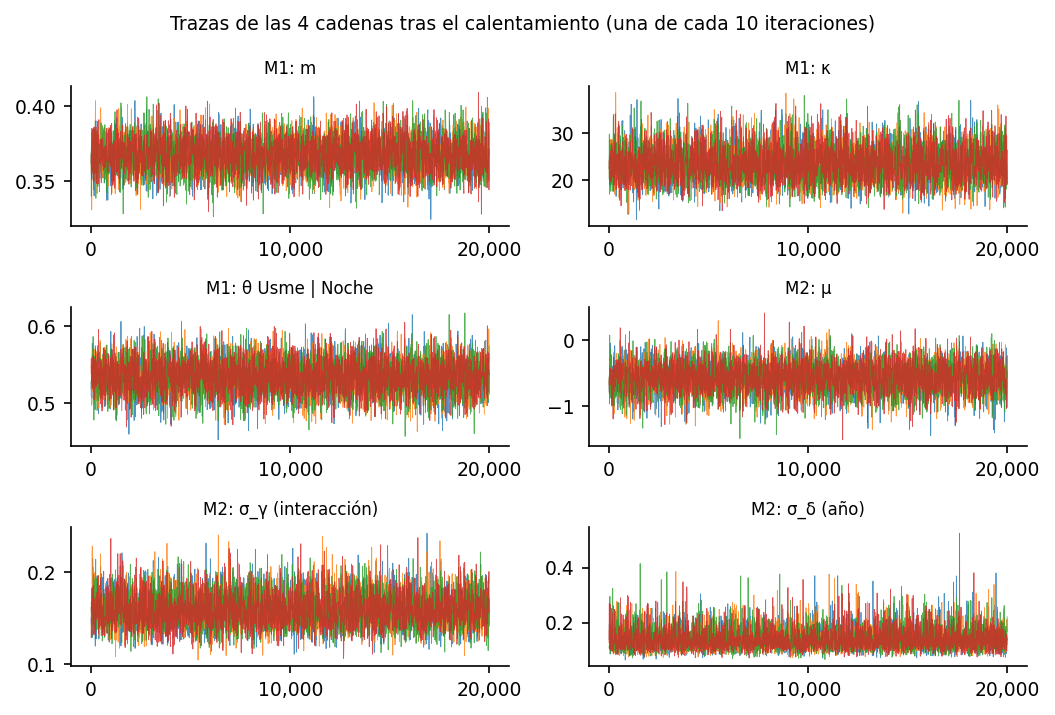

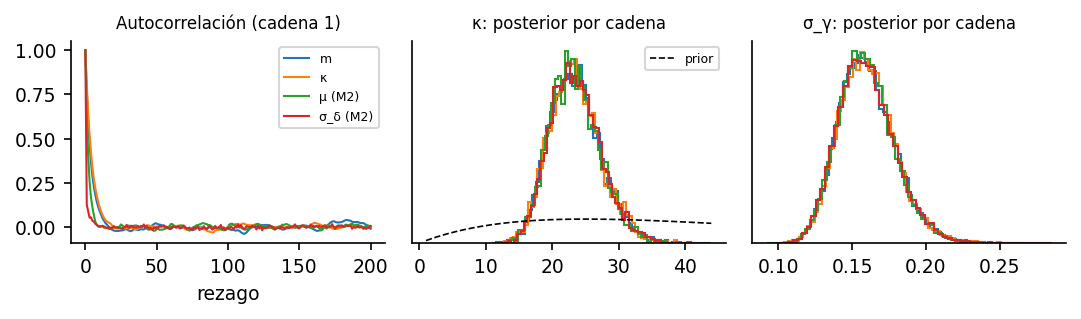

In [3]:
# Figura 6: trazas; Figura 7: autocorrelación y densidades por cadena
fig, axs = plt.subplots(3, 2, figsize=(7.2, 4.8))
series = [("M1: m", a1["m"]), ("M1: κ", a1["kappa"]), ("M1: θ Usme | Noche", a1["theta_usme"]),
          ("M2: μ", a2["mu"]), ("M2: σ_γ (interacción)", a2["sigma_g"]), ("M2: σ_δ (año)", a2["sigma_d"])]
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for ax, (tit, x) in zip(axs.ravel(), series):
    for c in range(K):
        ax.plot(x[c, ::10], lw=0.4, color=colores[c], alpha=0.8)
    ax.set_title(tit, fontsize=8)
    ax.set_xticks([0, ITER // 20, ITER // 10], ["0", f"{ITER // 2:,}", f"{ITER:,}"])
fig.suptitle("Trazas de las 4 cadenas tras el calentamiento (una de cada 10 iteraciones)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "trazas.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.2))
for tit, x in (("m", a1["m"]), ("κ", a1["kappa"]), ("μ (M2)", a2["mu"]), ("σ_δ (M2)", a2["sigma_d"])):
    z = x[0] - x[0].mean()
    ac = np.correlate(z, z, "full")[len(z) - 1:len(z) + 200] / (z.var() * len(z))
    axs[0].plot(ac, lw=1, label=tit)
axs[0].set_title("Autocorrelación (cadena 1)", fontsize=8); axs[0].legend(fontsize=6); axs[0].set_xlabel("rezago")
for c in range(K):
    axs[1].hist(a1["kappa"][c], bins=60, histtype="step", density=True, color=colores[c])
    axs[2].hist(a2["sigma_g"][c], bins=60, histtype="step", density=True, color=colores[c])
xs = np.linspace(1, a1["kappa"].max(), 200)
axs[1].plot(xs, st.gamma(2, scale=25).pdf(xs), "k--", lw=0.8, label="prior")
axs[1].set_title("κ: posterior por cadena", fontsize=8); axs[1].legend(fontsize=6)
axs[2].set_title("σ_γ: posterior por cadena", fontsize=8)
for ax in axs[1:]:
    ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "autocorr_densidades.png"); plt.show()

In [4]:
# Tabla por celda: severidad, intervalos, P(top 10), niveles de prioridad
pt1, pt2, pmay2 = a1['p_top10'], a2['p_top10'], a2['p_mayor_ciudad']
nivel = np.where(pmay2 > 0.95, "Alta", np.where(pmay2 < 0.05, "Baja", "Intermedia"))
nivel = np.where(n_tr < 30, "No concluyente", nivel)
tab = c_tr.rename(columns={"n": "n_2015_2017", "y": "graves_2015_2017"}).copy()
tab["p_cruda"] = p_cruda_tr
tab["M1_media"], tab["M1_q05"], tab["M1_q95"] = p1, a1['q05'], a1['q95']
tab["M2_media"], tab["M2_q05"], tab["M2_q95"] = p2, a2['q05'], a2['q95']
tab["M2_P_top10"], tab["M1_P_top10"] = pt2, pt1
tab["M2_P_mayor_ciudad"], tab["nivel"] = pmay2, nivel
tab["n_2018_2019"], tab["graves_2018_2019"] = n_te, y_te
tab["p_obs_2018_2019"] = obs_te
tab["elegible"] = eleg
tab["rank_conteo"] = (-y_tr).argsort().argsort() + 1
tab["rank_M2"] = (-p2).argsort().argsort() + 1
tab.to_csv(RES / "celdas_posterior.csv", index=False, encoding="utf-8-sig")
R["niveles"] = tab.nivel.value_counts().to_dict()
R["prioridad1_P_top10_ge_05"] = int((pt2 >= 0.5).sum())
R["P_top10_mayor_09"] = int((pt2 > 0.9).sum())
R["P_top10_entre_01_05"] = int(((pt2 >= 0.1) & (pt2 < 0.5)).sum())
R["prioridad2"] = int(((nivel == "Alta") & (pt2 < 0.5)).sum())
R["menor_n_en_prioridad1"] = int(n_tr[pt2 >= 0.5].min())
R["rho_M2_vs_conteo"] = float(st.spearmanr(p2[eleg], y_tr[eleg])[0])
R["rho_M1_vs_M2"] = float(st.spearmanr(p1[eleg], p2[eleg])[0])
R["encogimiento_max_pp_M2"] = float(np.max(np.abs(p2 - p_cruda_tr)[n_tr >= 30]) * 100)
R["rango_M2"] = [tab.loc[eleg].sort_values("M2_media").iloc[[0, -1]][["localidad", "franja", "M2_media", "M2_q05", "M2_q95"]].round(3).to_dict("records")]
print(limpio({k: R[k] for k in R if k != "rango_M2"}))
tab.sort_values("M2_media", ascending=False).head(10)[["localidad", "franja", "n_2015_2017", "M2_media", "M2_q05", "M2_q95", "M2_P_top10", "p_obs_2018_2019", "rank_conteo"]].round(3)

{'datos': {'p_tr': 0.32838, 'p_te': 0.36101}, 'niveles': {'Alta': 41, 'Baja': 24, 'Intermedia': 10, 'No concluyente': 5}, 'prioridad1_P_top10_ge_05': 9, 'P_top10_mayor_09': 5, 'P_top10_entre_01_05': 7, 'prioridad2': 32, 'menor_n_en_prioridad1': 502, 'rho_M2_vs_conteo': -0.19035, 'rho_M1_vs_M2': 0.99058, 'encogimiento_max_pp_M2': 4.53443}


,localidad,franja,n_2015_2017,M2_media,M2_q05,M2_q95,M2_P_top10,p_obs_2018_2019,rank_conteo
47,Rafael Uribe Uribe,Noche (18-24),705,0.547,0.473,0.619,1.000,0.533,37
79,Usme,Noche (18-24),502,0.534,0.458,0.608,0.990,0.525,54
51,San Cristóbal,Noche (18-24),636,0.531,0.457,0.605,0.993,0.548,45
49,San Cristóbal,Mañana (6-12),808,0.521,0.448,0.594,0.986,0.573,34
50,San Cristóbal,Tarde (12-18),832,0.510,0.437,0.582,0.923,0.484,33
11,Bosa,Noche (18-24),1172,0.501,0.429,0.571,0.849,0.488,18
46,Rafael Uribe Uribe,Tarde (12-18),891,0.496,0.423,0.568,0.740,0.507,31
45,Rafael Uribe Uribe,Mañana (6-12),807,0.494,0.421,0.566,0.681,0.565,35
19,Ciudad Bolívar,Noche (18-24),1031,0.487,0.416,0.559,0.545,0.522,24
3,Antonio Nariño,Noche (18-24),494,0.481,0.406,0.557,0.406,0.523,57


In [5]:
# Tabla 2 del informe: validación con 2018-2019 (se mira una sola vez)
val = {"Ciudad (agrupamiento completo)": metricas(p_city),
       "Proporción cruda (sin agrupamiento)": metricas(p_cruda_tr),
       "M1 Beta-Binomial jerárquico": metricas(p1, theta_thin=a1["thin20"]),
       "M2 Logística jerárquica": metricas(p2, theta_thin=a2["thin20"])}
rho_conteo = float(st.spearmanr(y_tr[eleg], obs_te[eleg])[0])
top_c = set(idx_e[np.argsort(-y_tr[idx_e])[:10]])
top_o = set(idx_e[np.argsort(-obs_te[idx_e])[:10]])
val["Conteo de graves (criterio actual)"] = dict(spearman=rho_conteo, top10=len(top_c & top_o))
R["validacion"] = val
cr = val["Proporción cruda (sin agrupamiento)"]["brier"]
R["criterios"] = {k: dict(spearman_ok=val[k]["spearman"] >= 0.90, brier_ok=val[k]["brier"] <= cr, top10_ok=val[k]["top10"] >= 6)
                  for k in ("M1 Beta-Binomial jerárquico", "M2 Logística jerárquica")}
shift = sp.logit(y_te.sum() / n_te.sum()) - sp.logit(y_tr.sum() / n_tr.sum())
R["brier_M2_nivel_corregido"] = metricas(sp.expit(sp.logit(p2) + shift))["brier"]
R["brier_cruda_nivel_corregido"] = metricas(sp.expit(sp.logit(np.clip(p_cruda_tr, 1e-3, 1 - 1e-3)) + shift))["brier"]
pd.DataFrame(val).T.to_csv(RES / "validacion_2018_2019.csv", encoding="utf-8-sig")
print("Criterios de éxito:", R["criterios"])
pd.DataFrame(val).T[["brier", "logloss", "spearman", "top10", "lpd", "cobertura90"]].round(5)

Criterios de éxito: {'M1 Beta-Binomial jerárquico': {'spearman_ok': True, 'brier_ok': True, 'top10_ok': True}, 'M2 Logística jerárquica': {'spearman_ok': True, 'brier_ok': True, 'top10_ok': True}}


C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\comun.py:94: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = float(st.spearmanr(p[eleg_], obs[eleg_])[0])


,brier,logloss,spearman,top10,lpd,cobertura90
Ciudad (agrupamiento completo),0.23175,0.65637,NaN,1.0,NaN,NaN
Proporción cruda (sin agrupamiento),0.22181,0.63486,0.92136,6.0,NaN,NaN
M1 Beta-Binomial jerárquico,0.22179,0.63462,0.92262,6.0,-429.68151,0.49367
M2 Logística jerárquica,0.22169,0.63439,0.93308,6.0,-375.29732,0.94937
Conteo de graves (criterio actual),NaN,NaN,-0.32901,0.0,NaN,NaN


In [6]:
# Equidad del error (umbral de 3 puntos fijado en el Avance 2) y capacidad de 10 celdas
v = val["M2 Logística jerárquica"]
eq = pd.DataFrame({g: [100 * v[f"mae_{g}"], 100 * v[f"mae_no_{g}"], 100 * (v[f"mae_{g}"] - v[f"mae_no_{g}"]), 100 * v[f"sesgo_{g}"]]
                   for g in ("sur", "noche_madrug", "pequenas")}, index=["MAE grupo", "MAE resto", "diferencia (pp)", "sesgo grupo"]).round(2)
print(f"Piso binomial: pequeñas {100*v['piso_mae_pequenas']:.2f} pp, grandes {100*v['piso_mae_grandes']:.2f} pp; "
      f"exceso sobre el piso: {100*(v['mae_pequenas']-v['piso_mae_pequenas']):.2f} vs {100*(v['mae_no_pequenas']-v['piso_mae_grandes']):.2f} pp")
e = tab[tab.elegible]
cap = {}
for nom, s_ in (("M2", e.nlargest(10, "M2_media")), ("conteo", e.nlargest(10, "graves_2015_2017"))):
    cap[nom] = dict(siniestros=int(s_.n_2018_2019.sum()), graves=int(s_.graves_2018_2019.sum()),
                    pct=s_.graves_2018_2019.sum() / s_.n_2018_2019.sum())
cap["coinciden"] = len(set(e.nlargest(10, "M2_media").index) & set(e.nlargest(10, "graves_2015_2017").index))
R["capacidad_10_celdas"] = cap
print("Capacidad 10 celdas (2018-2019):", limpio(cap))
eq

Piso binomial: pequeñas 2.99 pp, grandes 1.29 pp; exceso sobre el piso: 3.70 vs 2.16 pp
Capacidad 10 celdas (2018-2019): {'M2': {'siniestros': 6048, 'graves': 3169, 'pct': 0.52397}, 'conteo': {'siniestros': 21016, 'graves': 7755, 'pct': 0.369}, 'coinciden': 0}


,sur,noche_madrug,pequenas
MAE grupo,3.76,4.64,6.69
MAE resto,4.32,3.66,3.45
diferencia (pp),-0.56,0.98,3.24
sesgo grupo,-2.64,-4.08,-5.93


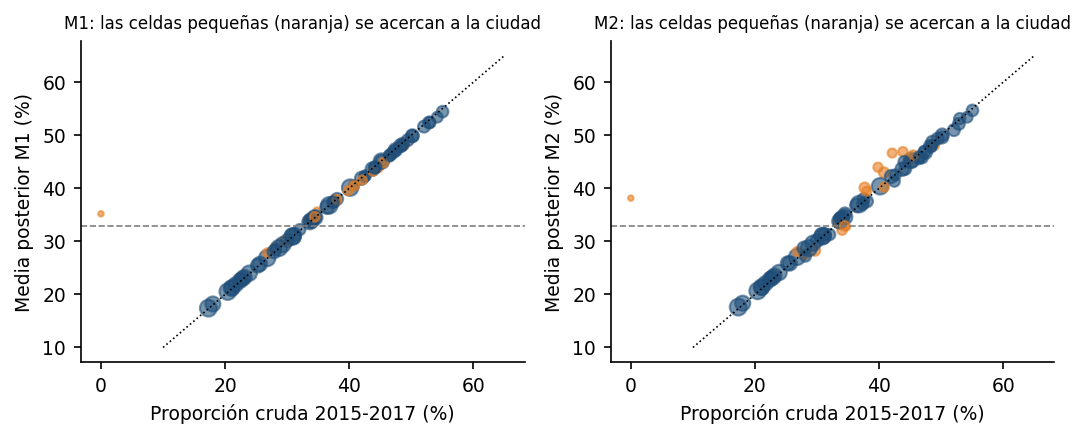

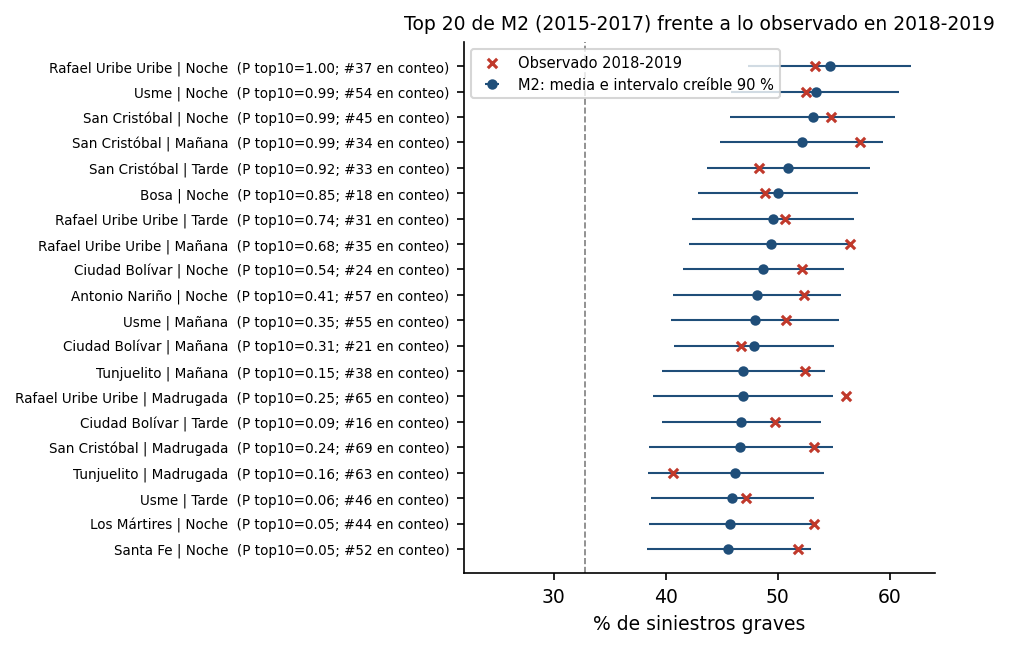

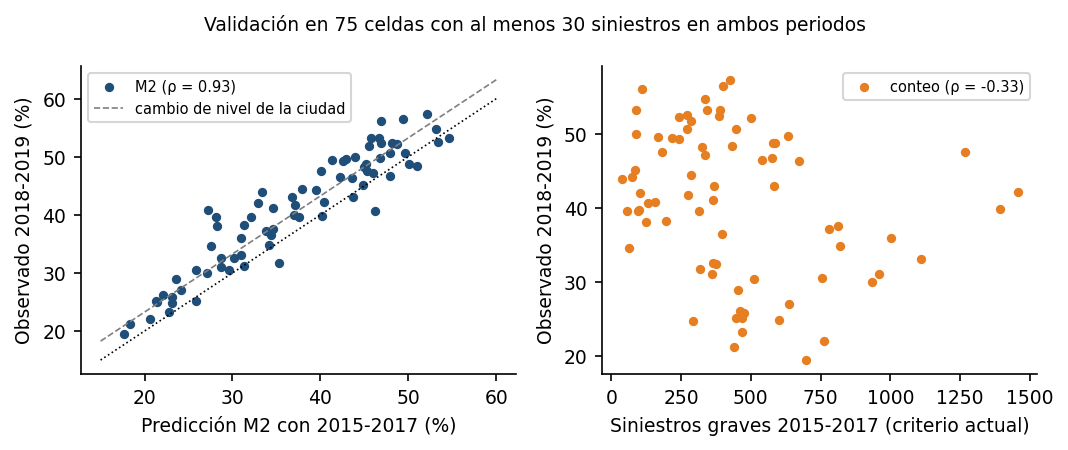

In [7]:
# Figura de encogimiento
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
for ax, p_, nom in ((axs[0], p1, "M1"), (axs[1], p2, "M2")):
    s_ = 6 + 60 * np.sqrt(n_tr / n_tr.max())
    ax.scatter(100 * p_cruda_tr[n_tr > 0], 100 * p_[n_tr > 0], s=s_[n_tr > 0], alpha=0.6,
               c=np.where(n_tr[n_tr > 0] < 500, NARANJA, AZUL))
    ax.plot([10, 65], [10, 65], "k:", lw=0.8)
    ax.axhline(100 * p_city[0], color=GRIS, ls="--", lw=0.8)
    ax.set_xlabel("Proporción cruda 2015-2017 (%)")
    ax.set_ylabel(f"Media posterior {nom} (%)")
    ax.set_title(f"{nom}: las celdas pequeñas (naranja) se acercan a la ciudad", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "encogimiento.png")
plt.show()

# Forest plot del top 20 de M2
top20 = tab.sort_values("M2_media", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.4))
yy = np.arange(len(top20))
ax.errorbar(100 * top20.M2_media, yy, xerr=[100 * (top20.M2_media - top20.M2_q05), 100 * (top20.M2_q95 - top20.M2_media)],
            fmt="o", color=AZUL, ms=4, lw=1, label="M2: media e intervalo creíble 90 %")
ax.scatter(100 * top20.p_obs_2018_2019, yy, marker="x", color=ROJO, s=20, zorder=3, label="Observado 2018-2019")
ax.set_yticks(yy, [f"{a} | {b.split(' ')[0]}  (P top10={p:.2f}; #{r} en conteo)"
                   for a, b, p, r in zip(top20.localidad, top20.franja, top20.M2_P_top10, top20.rank_conteo)], fontsize=6.5)
ax.axvline(100 * R["datos"]["p_tr"], color=GRIS, ls="--", lw=0.8)
ax.set_xlabel("% de siniestros graves")
ax.legend(fontsize=7, loc="upper left")
ax.set_xlim(22, 64)
ax.set_title("Top 20 de M2 (2015-2017) frente a lo observado en 2018-2019", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "top20_forest.png")
plt.show()

# Figura de validación: predicción vs observado y orden por conteo
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
e = eleg
axs[0].scatter(100 * p2[e], 100 * obs_te[e], s=12, color=AZUL, label=f"M2 (ρ = {val['M2 Logística jerárquica']['spearman']:.2f})")
axs[0].plot([15, 60], [15, 60], "k:", lw=0.8)
axs[0].plot([15, 60], [15 + 100 * (R['datos']['p_te'] - R['datos']['p_tr']), 60 + 100 * (R['datos']['p_te'] - R['datos']['p_tr'])],
            color=GRIS, ls="--", lw=0.8, label="cambio de nivel de la ciudad")
axs[0].set_xlabel("Predicción M2 con 2015-2017 (%)")
axs[0].set_ylabel("Observado 2018-2019 (%)")
axs[0].legend(fontsize=7)
axs[1].scatter(y_tr[e], 100 * obs_te[e], s=12, color=NARANJA, label=f"conteo (ρ = {rho_conteo:.2f})")
axs[1].set_xlabel("Siniestros graves 2015-2017 (criterio actual)")
axs[1].set_ylabel("Observado 2018-2019 (%)")
axs[1].legend(fontsize=7)
fig.suptitle(f"Validación en {e.sum()} celdas con al menos 30 siniestros en ambos periodos", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "validacion.png")
plt.show()

In [8]:
# Verificación contra el informe (si algo no coincide, la celda falla)
m2v = val["M2 Logística jerárquica"]
esperado = {"Spearman M2": (round(m2v["spearman"], 3), 0.933), "Brier M2": (round(m2v["brier"], 5), 0.22169),
            "Top 10 M2": (m2v["top10"], 6), "Cobertura IC90 M2": (round(m2v["cobertura90"], 3), 0.949),
            "Spearman M1": (round(val["M1 Beta-Binomial jerárquico"]["spearman"], 3), 0.923),
            "Brier cruda": (round(cr, 5), 0.22181), "Spearman conteo": (round(rho_conteo, 3), -0.329),
            "Capacidad M2": ((cap["M2"]["siniestros"], cap["M2"]["graves"]), (6048, 3169)),
            "Capacidad conteo": ((cap["conteo"]["siniestros"], cap["conteo"]["graves"]), (21016, 7755))}
for k, (obtenido, informe) in esperado.items():
    print(f"{k:20s} notebook={obtenido}  informe={informe}  {'OK' if obtenido == informe else 'DIFERENTE'}")
assert all(o == i for o, i in esperado.values()), "Alguna cifra no coincide con el informe"
guardar_json(R, "07_validacion.json")

Spearman M2          notebook=0.933  informe=0.933  OK
Brier M2             notebook=0.22169  informe=0.22169  OK
Top 10 M2            notebook=6  informe=6  OK
Cobertura IC90 M2    notebook=0.949  informe=0.949  OK
Spearman M1          notebook=0.923  informe=0.923  OK
Brier cruda          notebook=0.22181  informe=0.22181  OK
Spearman conteo      notebook=-0.329  informe=-0.329  OK
Capacidad M2         notebook=(6048, 3169)  informe=(6048, 3169)  OK
Capacidad conteo     notebook=(21016, 7755)  informe=(21016, 7755)  OK
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\07_validacion.json
